*  DSC630-T303 Predictive Analytics (2267-1)
*  3.2 Assignment: Using Data to Improve MLB Attendance
*  David Jorgensen

# 3.2 Assignment: Using Data to Improve MLB Attendance

## Business problem and approach

Los Angeles Dodgers management wants to know **how to improve ballpark attendance**.
Using a single season of home-game records, this analysis looks for the game-day
characteristics that are *associated* with larger crowds, then turns those
associations into practical, evidence-proportional recommendations.

**Important framing.** This is observational, single-season data. Promotions and
schedule slots are not randomly assigned, so every result below is reported as an
**association, not a cause**. Where a finding rests on only a handful of games, the
sample size is stated so the reader can judge how much weight it deserves.

### Research questions
1. **Promotions**: Are giveaway/entertainment promotions (bobblehead, cap, shirt, fireworks) associated with higher attendance?
2. **Scheduling**: Are some days of the week, months, or day-vs-night slots associated with higher attendance?
3. **Game environment**: Are weather (temperature, skies) or the visiting opponent associated with attendance?

### Data source
Los Angeles Dodgers 2022 home-game data, **provided by Bellevue University for the
DSC630-T303 (Predictive Analytics) course**. The original provenance of the dataset
was not specified by the course. Source link:
<https://content.bellevue.edu/cst/dsc/630/dodgers-2022.csv>


## 1. Load the data and libraries

In [1]:
# Core libraries for data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

# Load the Dodgers home-game data provided by Bellevue University (DSC630-T303)
df = pd.read_csv("data/dodgers-2022.csv")

# Quick look at the first rows
df.head()


,month,day,attend,day_of_week,opponent,temp,skies,day_night,cap,shirt,fireworks,bobblehead
0,APR,10,56000,Tuesday,Pirates,67,Clear,Day,NO,NO,NO,NO
1,APR,11,29729,Wednesday,Pirates,58,Cloudy,Night,NO,NO,NO,NO
2,APR,12,28328,Thursday,Pirates,57,Cloudy,Night,NO,NO,NO,NO
3,APR,13,31601,Friday,Padres,54,Cloudy,Night,NO,NO,YES,NO
4,APR,14,46549,Saturday,Padres,57,Cloudy,Night,NO,NO,NO,NO


## 2. Understand and clean the data

Each row is a single home game. We confirm the shape, data types, and check for
missing values and obvious formatting issues before analysis.

In [2]:
# Structure and data types
print("Rows, columns:", df.shape)
df.info()


Rows, columns: (81, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   month        81 non-null     object
 1   day          81 non-null     int64 
 2   attend       81 non-null     int64 
 3   day_of_week  81 non-null     object
 4   opponent     81 non-null     object
 5   temp         81 non-null     int64 
 6   skies        81 non-null     object
 7   day_night    81 non-null     object
 8   cap          81 non-null     object
 9   shirt        81 non-null     object
 10  fireworks    81 non-null     object
 11  bobblehead   81 non-null     object
dtypes: int64(3), object(9)
memory usage: 7.7+ KB


In [3]:
# Check for missing values in every column
df.isna().sum()


month          0
day            0
attend         0
day_of_week    0
opponent       0
temp           0
skies          0
day_night      0
cap            0
shirt          0
fireworks      0
bobblehead     0
dtype: int64

In [4]:
# The 'skies' field has trailing whitespace (e.g. 'Clear ') that would split
# the same category into two groups. Strip it so grouping is clean.
df["skies"] = df["skies"].str.strip()

# Put months in calendar order (not alphabetical) for readable charts
month_order = ["APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT"]
df["month"] = pd.Categorical(df["month"], categories=month_order, ordered=True)

# Put days of week in week order
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=dow_order, ordered=True)

# Confirm the promotion / categorical columns and their value counts
for col in ["day_night", "skies", "cap", "shirt", "fireworks", "bobblehead"]:
    print(col, "->", df[col].value_counts().to_dict())


day_night -> {'Night': 66, 'Day': 15}
skies -> {'Clear': 62, 'Cloudy': 19}
cap -> {'NO': 79, 'YES': 2}
shirt -> {'NO': 78, 'YES': 3}
fireworks -> {'NO': 67, 'YES': 14}
bobblehead -> {'NO': 70, 'YES': 11}


**Data notes.** The season has **81 home games** (the full MLB home schedule) with
no missing values. `skies` carried trailing spaces that were trimmed. The promotion
columns are Yes/No flags; note already that some promotions occur very rarely
(`cap` and `shirt` in particular), which limits how far we can interpret them.

## 3. Overall attendance

Before comparing groups, establish the baseline distribution of attendance.

count       81.0
mean     41040.0
std       8298.0
min      24312.0
25%      34493.0
50%      40284.0
75%      46588.0
max      56000.0
Name: attend, dtype: float64


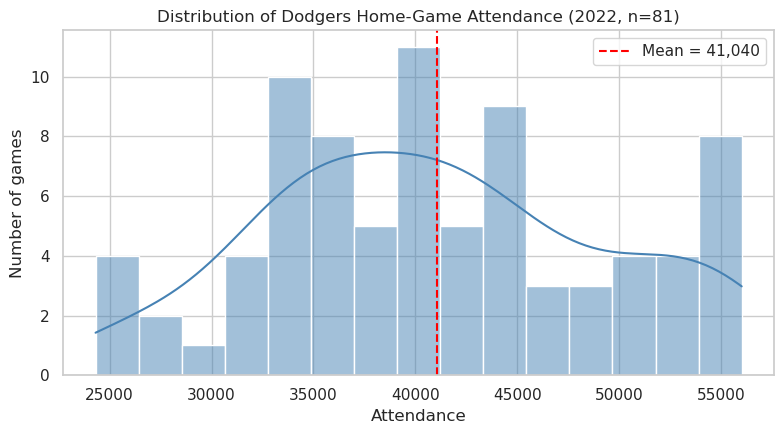

In [5]:
# Summary statistics for attendance
print(df["attend"].describe().round(0))

# Distribution of attendance across the 81 games
plt.figure()
sns.histplot(df["attend"], bins=15, kde=True, color="steelblue")
plt.axvline(df["attend"].mean(), color="red", linestyle="--",
            label=f"Mean = {df['attend'].mean():,.0f}")
plt.title("Distribution of Dodgers Home-Game Attendance (2022, n=81)")
plt.xlabel("Attendance")
plt.ylabel("Number of games")
plt.legend()
plt.tight_layout()
plt.show()


**Observation.** Attendance ranges from about **24,300 to 56,000** (the high end is the stadium's effective capacity), averaging roughly **41,000** per game. The top of the range bumping against ~56,000 means the highest-demand games are likely **capacity-constrained**, which is a point that matters when interpreting the promotions below.

## 4. Research question 1: Promotions

Compare mean attendance for games with vs. without each promotion. Sample sizes are
shown because some promotions are rare.


bobblehead
               mean  count
bobblehead                
NO          39138.0     70
YES         53145.0     11

cap
        mean  count
cap                
NO   41112.0     79
YES  38190.0      2

shirt
          mean  count
shirt                
NO     40825.0     78
YES    46644.0      3

fireworks
              mean  count
fireworks                
NO         41032.0     67
YES        41078.0     14


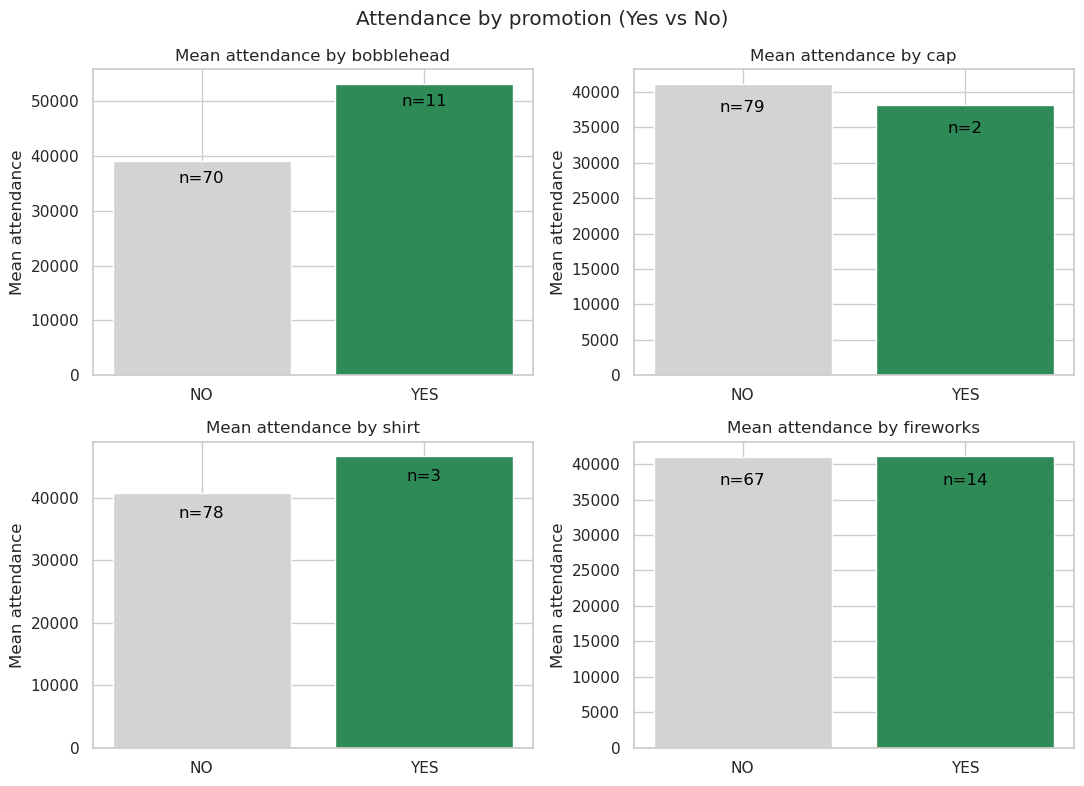

In [6]:
promos = ["bobblehead", "cap", "shirt", "fireworks"]

# Mean attendance and game count for each promotion (Yes vs No)
summary = []
for p in promos:
    g = df.groupby(p, observed=True)["attend"].agg(["mean", "count"])
    summary.append(g)
    print(f"\n{p}\n{g.round(0)}")

# Bar chart of mean attendance with vs without each promotion
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, p in zip(axes.ravel(), promos):
    g = df.groupby(p, observed=True)["attend"].mean()
    counts = df.groupby(p, observed=True)["attend"].count()
    bars = ax.bar(g.index, g.values, color=["lightgray", "seagreen"])
    ax.set_title(f"Mean attendance by {p}")
    ax.set_ylabel("Mean attendance")
    # annotate each bar with the underlying game count (n)
    for bar, idx in zip(bars, g.index):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 4000,
                f"n={counts[idx]}", ha="center", color="black")
fig.suptitle("Attendance by promotion (Yes vs No)")
fig.tight_layout()
plt.show()


**Observations and interpretation (associations only).**

- **Bobblehead nights stand out.** Games with a bobblehead giveaway averaged about
  **53,100** vs **39,100** without: roughly a **+14,000** difference, on **n=11**
  bobblehead games. This is the largest and best-supported promotional association in
  the data. Several of these games sit near the ~56,000 capacity ceiling, so the true
  demand may be *understated* by the cap.
- **Fireworks look flat *unadjusted*** (~41,100 vs ~41,000, n=14), but this hides a
  scheduling pattern: **13 of the 14 fireworks nights were Fridays**. Friday is a
  relatively soft slot, so a fireworks night landing at roughly the league-average
  crowd may actually be *propping up an otherwise-weak date*. The Section 7 regression
  revisits this; but because fireworks and "Friday" almost perfectly overlap, the two
  effects cannot be cleanly separated.
- **Cap (n=2) and shirt (n=3) giveaways are too rare to interpret.** Their means swing
  on a couple of games and should not drive any decision; they are reported for
  completeness only.

*Caveat:* bobblehead nights are not randomly scheduled. The team may already place
them on dates expected to draw well (weekends, marquee opponents). The regression in
Section 7 partially controls for this.

## 5. Research question 2: Scheduling (day, month, day/night)

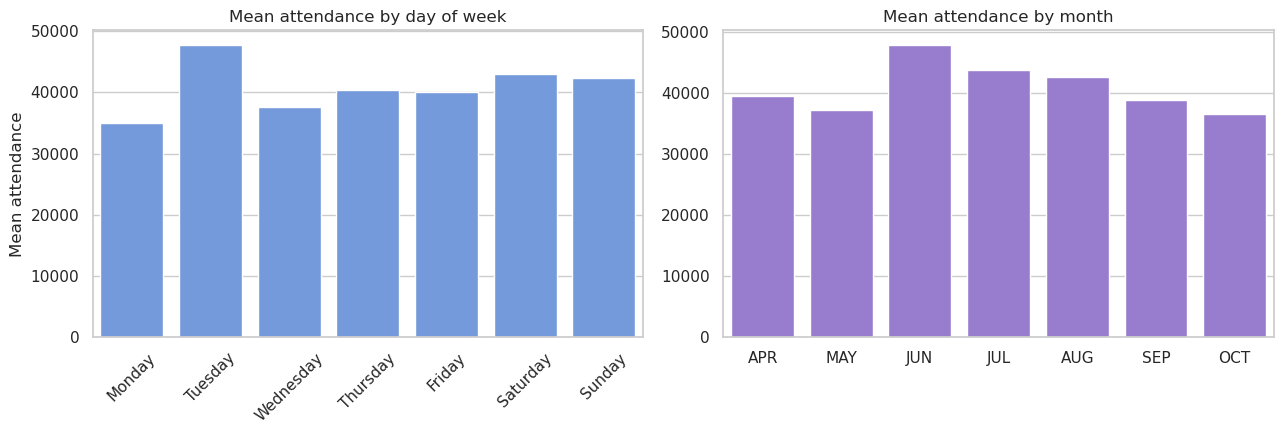

Games per day of week:
 day_of_week
Monday       12
Tuesday      13
Wednesday    12
Thursday      5
Friday       13
Saturday     13
Sunday       13
Name: count, dtype: int64

Games per month:
 month
APR    12
MAY    18
JUN     9
JUL    12
AUG    15
SEP    12
OCT     3
Name: count, dtype: int64

Day vs Night:
               mean  count
day_night                
Day        41793.0     15
Night      40869.0     66


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Mean attendance by day of week
sns.barplot(data=df, x="day_of_week", y="attend", estimator="mean",
            errorbar=None, ax=axes[0], color="cornflowerblue", order=dow_order)
axes[0].set_title("Mean attendance by day of week")
axes[0].set_xlabel(""); axes[0].set_ylabel("Mean attendance")
axes[0].tick_params(axis="x", rotation=45)

# Mean attendance by month
sns.barplot(data=df, x="month", y="attend", estimator="mean",
            errorbar=None, ax=axes[1], color="mediumpurple", order=month_order)
axes[1].set_title("Mean attendance by month")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# Game counts behind each group, and the day vs night comparison
print("Games per day of week:\n", df["day_of_week"].value_counts().reindex(dow_order))
print("\nGames per month:\n", df["month"].value_counts().reindex(month_order))
print("\nDay vs Night:\n", df.groupby("day_night", observed=True)["attend"].agg(["mean", "count"]).round(0))


**Observations and interpretation (associations only).**

- **Day of week:** **Tuesday** averaged the highest (~47,700) and **Monday** the lowest
  (~35,000); weekends (Sat ~43,100, Sun ~42,300) were solid. Each weekday has only
  ~12–13 games, so differences are suggestive rather than definitive. The Tuesday peak
  is partly explained by promotions: many bobblehead nights fell on Tuesdays.
- **Month:** **June/July** were the strongest (~44,000–48,000) and **May/October** the
  weakest (~37,000), consistent with a summer/school-vacation pattern. October has only
  3 games, so its low mean is fragile.
- **Day vs night:** little difference (~41,800 day vs ~40,900 night). Slot of day is
  not, on its own, associated with materially different attendance here.

## 6. Research question 3: Game environment (weather and opponent)

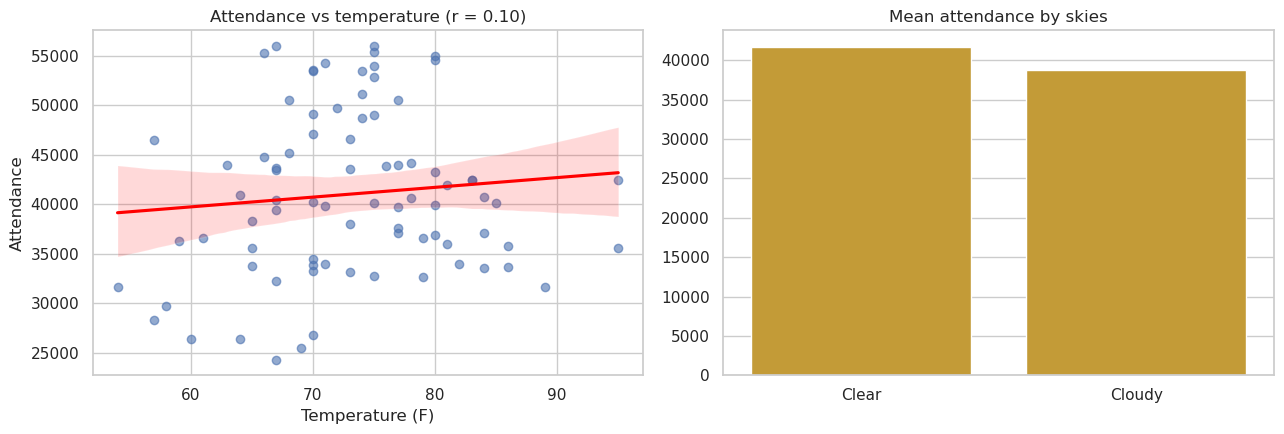

Skies counts:
            mean  count
skies                 
Clear   41729.0     62
Cloudy  38791.0     19


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Temperature vs attendance
sns.regplot(data=df, x="temp", y="attend", ax=axes[0],
            scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
axes[0].set_title(f"Attendance vs temperature (r = {df['attend'].corr(df['temp']):.2f})")
axes[0].set_xlabel("Temperature (F)"); axes[0].set_ylabel("Attendance")

# Skies (clear vs cloudy)
sns.barplot(data=df, x="skies", y="attend", estimator="mean",
            errorbar=None, ax=axes[1], color="goldenrod")
axes[1].set_title("Mean attendance by skies")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

print("Skies counts:\n", df.groupby("skies", observed=True)["attend"].agg(["mean", "count"]).round(0))


              mean  count
opponent                 
Angels     49777.0      3
Mets       49586.0      4
Nationals  49267.0      3
White Sox  46382.0      3
Cubs       44207.0      3
Padres     42092.0      9
Phillies   41897.0      3
Cardinals  40853.0      7
Marlins    40665.0      3
Reds       40649.0      3
Rockies    39631.0      9
Snakes     39315.0      9
Giants     39296.0      9
Pirates    38019.0      3
Astros     35383.0      3
Brewers    35359.0      4
Braves     32245.0      3


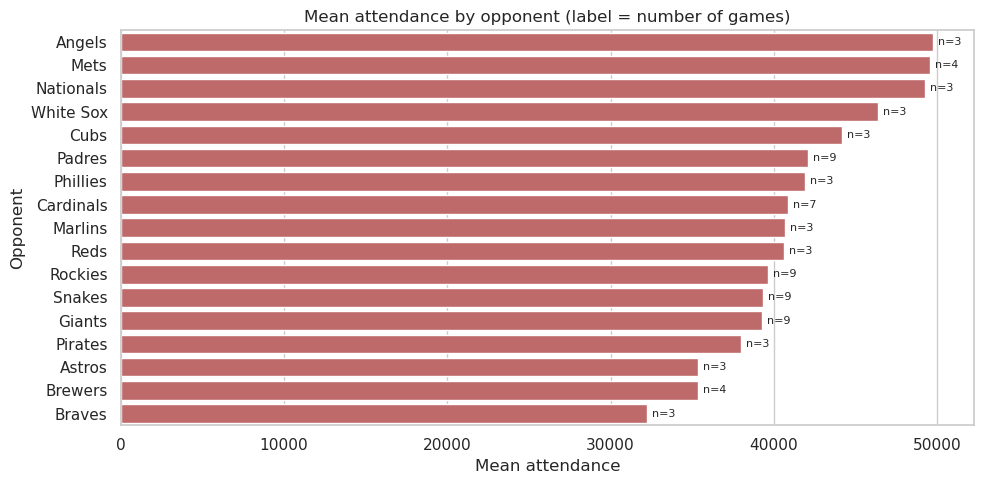

In [9]:
# Opponent: which visiting teams drew the biggest / smallest crowds
opp = df.groupby("opponent", observed=True)["attend"].agg(["mean", "count"]).sort_values("mean", ascending=False)
print(opp.round(0))

plt.figure(figsize=(10, 5))
sns.barplot(x=opp["mean"], y=opp.index, color="indianred")
plt.title("Mean attendance by opponent (label = number of games)")
plt.xlabel("Mean attendance"); plt.ylabel("Opponent")
# annotate each bar with the number of games against that opponent
for i, (m, c) in enumerate(zip(opp["mean"], opp["count"])):
    plt.text(m + 300, i, f"n={c}", va="center", fontsize=8)
plt.tight_layout()
plt.show()


**Observations and interpretation (associations only).**

- **Temperature** has a **very weak** positive correlation with attendance (**r ≈ 0.10**).
  Warmer games are not meaningfully better attended once everything else varies.
- **Skies:** clear-sky games averaged a bit higher (~41,700, n=62) than cloudy ones
  (~38,800, n=19), but skies are recorded at game time and may simply track season/time
  of day rather than driving fan decisions.
- **Opponent** matters but on **tiny per-team samples** (most opponents appear in only
  3–6 games). Divisional/marquee rivals (e.g., Giants, Mets, Angels, White Sox) tend to
  appear among the higher draws, but with so few games per opponent these rankings are
  unstable and should be read as directional only.

## 7. Putting it together: a simple multivariable model

A single ordinary-least-squares (OLS) regression lets us look at each factor while
holding the others roughly constant: for example, asking whether the bobblehead
association survives after accounting for day of week and month. With only **81 games**
and many categories, this model is **descriptive, not predictive**; coefficients are
associations, and small-sample categories (cap, shirt) remain unreliable.

In [10]:
import statsmodels.formula.api as smf

# Convert Yes/No promotions to 0/1
model_df = df.copy()
for p in promos:
    model_df[p] = (model_df[p] == "YES").astype(int)

# OLS: attendance explained by promotions, schedule, and weather
# C(...) treats a column as categorical with automatic reference levels
formula = ("attend ~ bobblehead + cap + shirt + fireworks + temp "
           "+ C(skies) + C(day_night) + C(day_of_week) + C(month)")
model = smf.ols(formula, data=model_df).fit()

# Show coefficient, std error, p-value for each term
print(model.summary().tables[1])
print("\nR-squared:", round(model.rsquared, 3),
      "| Adjusted R-squared:", round(model.rsquared_adj, 3))


                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                    2.831e+04   1.29e+04      2.187      0.033    2428.787    5.42e+04
C(skies)[T.Cloudy]           -776.4530   1971.978     -0.394      0.695   -4719.666    3166.760
C(day_night)[T.Night]        -639.8015   2891.568     -0.221      0.826   -6421.850    5142.247
C(day_of_week)[T.Tuesday]    8424.2658   2728.871      3.087      0.003    2967.551    1.39e+04
C(day_of_week)[T.Wednesday]  1593.0773   2595.940      0.614      0.542   -3597.825    6783.979
C(day_of_week)[T.Thursday]   1380.9098   3380.818      0.408      0.684   -5379.453    8141.273
C(day_of_week)[T.Friday]    -1.055e+04   7046.893     -1.497      0.140   -2.46e+04    3541.372
C(day_of_week)[T.Saturday]   7033.1800   2503.378      2.809      0.007    2027.366     1.2e+04
C(day_of_week)[T.Sunday]     6094.9080  

**Reading the model** (R² ≈ 0.62, adjusted ≈ 0.50).

- **Bobblehead** is the standout: even holding day of week, month, and weather constant,
  its coefficient stays large and positive (**≈ +10,600 seats, p < 0.001**). The
  association is *not* just an artifact of when bobblehead nights are scheduled.
- **Tuesday (+8,400) and Saturday (+7,000)** are significantly above the Monday baseline,
  echoing the Section 5 pattern.
- **Fireworks** shows a large positive coefficient (≈ +16,200, p = 0.02), while **Friday**
  shows a large *negative* one (≈ −10,600). Read together, these two are an artifact of
  collinearity (**13 of 14 fireworks games are Fridays**), so the model is splitting one
  Friday-night effect into two offsetting pieces with wide error bars. The honest takeaway
  is *not* "fireworks add 16,000 seats," but rather that **fireworks appear to lift
  otherwise-soft Friday dates back toward average**; the data cannot isolate a standalone
  fireworks effect.
- **Cap and shirt** coefficients rest on 2–3 games, so their wide uncertainty makes them
  uninformative. Temperature and skies are not significant.

Overall the model explains a moderate share of variation; much of game-to-game attendance
is driven by factors not captured here (standings, pitching matchups, ticket pricing,
opponent star power).

## 8. Conclusion and recommendations

Organized by research question: the answer, the visual evidence behind it, and its
limitations. All findings are **associations** observed in **one 81-game season**, not
proven causes.

### Q1: Promotions
**Answer:** **Bobblehead giveaways are strongly associated with higher attendance**
(~53,100 vs ~39,100; ~+14,000 unadjusted, and ~+10,600 after adjustment, p < 0.001).
Fireworks *look* flat on their own but are almost entirely Friday-night events, so their
effect cannot be separated from the Friday slot, best read as helping prop up a soft
date rather than adding crowds outright. Cap and shirt giveaways are too rare (n=2, n=3)
to judge.
**Evidence:** Section 4 bar charts and the Section 7 regression coefficients.
**Limitation:** bobblehead nights are scheduled deliberately and several hit the
~56,000 capacity cap, so the effect is partly confounded and possibly understated;
fireworks are collinear with Friday.

### Q2: Scheduling
**Answer:** **Tuesday and weekend games, and the summer months (June–July),** are
associated with the best crowds; Mondays and the shoulder months (May, October) are
weakest. Day-vs-night makes little difference.
**Evidence:** Section 5 day-of-week and month bar charts; Section 7 (Tuesday +8,400,
Saturday +7,000 vs Monday baseline).
**Limitation:** ~12–13 games per weekday and as few as 3 games in October; the Tuesday
peak overlaps with bobblehead scheduling.

### Q3: Game environment
**Answer:** Weather is, at most, **weakly associated** with attendance (temperature
r ≈ 0.10, not significant; clear skies slightly higher). Opponent appears to matter 
(rivals/marquee teams draw more), but per-opponent samples are too small for firm
conclusions.
**Evidence:** Section 6 scatter/bar charts.
**Limitation:** weather is measured at game time and most opponents appear in only 3–6 games.

### Recommendations to management
1. **Expand the bobblehead/collectible-giveaway program**. This is the clearest, largest, and
   most statistically robust attendance lever in the data. Schedule additional giveaway
   nights on **lower-demand slots (Mondays, May, early/late season)** where empty-seat
   upside is greatest, rather than on dates already pressed against the ~56,000 cap.
2. **Keep fireworks paired with soft Friday dates, and test them elsewhere.** Because
   fireworks and Fridays are entangled in this season, run them on a few *non-Friday*
   weak dates next season to learn whether the lift is from the fireworks or the slot.
3. **Anchor the heaviest promotion and marketing spend in the soft windows** (Mondays,
   May, October) to lift the games that need help, while protecting capacity revenue on
   already-strong summer weekends.
4. **Confirm before committing budget.** Because this is a single observational season
   with promotions confounded by scheduling, management should **run controlled tests
   across multiple seasons** (randomizing which dates get which promotion) to verify
   these associations reflect real causal lift.

### Data limitations (summary)
Single season, **81 games**, observational (no randomized promotions), promotions
confounded with scheduling (notably fireworks ≈ Fridays), several categories with very
small n (cap n=2, shirt n=3, October n=3, per-opponent 3–6), and a capacity ceiling
(~56,000) that censors demand on the biggest dates. These limits are why every conclusion
above is framed as an association and paired with a recommendation to validate
experimentally before large spending decisions.